# Descritiva das referências de custos de soja e milho

**Etapa 2 — inventário e diagnóstico, sem estimação de margens ou backcasting.**

Fonte: `../01_dados_primarios/CUSTOS_ORIGINAIS_SOJA_MILHO.csv`, publicado no commit `c9e1bbc2bd733912b31970ccd20eda2cf7280333`. O CSV reúne extratos existentes CONAB/IMEA; as planilhas oficiais não foram reextraídas. O dicionário e o LEIA_ME da etapa 1 fazem parte da interpretação.

Uma linha é uma **referência × conceito × unidade**, não um município-ano independente. CONAB contém custos modais/estimados por praça, com marcadores Ex-Ant; IMEA contém consolidados e referências mensais/estimativas. Nem a presença de praça municipal nem uma referência estadual equivale a custo médio observado de todos os produtores. O inventário inclui períodos fora de 2001–2024.

**Execução:** Python 3.10+, pandas, numpy, matplotlib, IPython; para executar automaticamente: nbformat, nbclient, ipykernel. Instale em ambiente virtual, abra este notebook no repositório e execute todas as células. Os caminhos são detectados a partir da pasta atual ou de seus ancestrais; nenhuma célula baixa dados ou grava no CSV. Tabelas e gráficos ficam incorporados nos outputs. Gráficos usam valores nominais e não medem variações reais de custos.

In [1]:
from pathlib import Path
import hashlib, json, sys, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown

REL = Path("2_INTI/chapters/chap1/stats/modelos/custos_soja_milho")
roots = [p for p in [Path.cwd(), *Path.cwd().parents] if (p / REL / "01_dados_primarios").is_dir()]
if not roots:
    raise FileNotFoundError("Abra o notebook dentro do repositório tese_eco_usp, preservando a estrutura das etapas 1 e 2.")
ROOT = roots[0]
BASE = ROOT / REL / "01_dados_primarios"
CSV = BASE / "CUSTOS_ORIGINAIS_SOJA_MILHO.csv"
sha_antes = hashlib.sha256(CSV.read_bytes()).hexdigest()
assert sha_antes == "c8b54903e52dd31062cf43365ac32347bdc17133c0e09b5af6436a7757a0e119", "A fonte mudou: revisar a versão antes de comparar resultados."
raw = pd.read_csv(CSV, dtype=str, keep_default_na=False)
dicionario = pd.read_csv(BASE / "DICIONARIO.csv", dtype=str, keep_default_na=False)
leia_me = (BASE / "LEIA_ME.md").read_text(encoding="utf-8")
assert set(raw.columns) == set(dicionario.campo)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 65)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print("Python:", sys.version.split()[0])
print({x:metadata.version(x) for x in ["pandas","numpy","matplotlib","nbformat","nbclient","ipykernel"]})
print("Fonte:", CSV.relative_to(ROOT), "\nSHA256:", sha_antes)
display(dicionario)


mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-v3f1qvbf because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


Python: 3.12.14
{'pandas': '2.2.3', 'numpy': '2.3.5', 'matplotlib': '3.10.8', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}
Fonte: 2_INTI/chapters/chap1/stats/modelos/custos_soja_milho/01_dados_primarios/CUSTOS_ORIGINAIS_SOJA_MILHO.csv 
SHA256: c8b54903e52dd31062cf43365ac32347bdc17133c0e09b5af6436a7757a0e119


,campo,descricao
0,id_registro,Chave técnica fonte + série + conceito + unidade; não é códig...
1,fonte,Instituição responsável: CONAB ou IMEA.
2,cultura,soja ou milho; sistema/safra preservados em cultura_sistema_o...
3,cultura_sistema_origem,Categoria preexistente; milho_1a/milho_2a CONAB; IMEA não har...
4,sistema_tecnologia,"Classificação ou rótulo preservado do extrato, sem inferência..."
5,localidade_aba,Localidade extraída da aba CONAB; vazio quando não disponível.
6,localidade_cabecalho,"Localidade do cabeçalho CONAB, inclusive conflito; vazio para..."
7,localidade_rotulo_original,"Rótulo geográfico IMEA; vazio para CONAB, cujas duas identifi..."
8,abrangencia_origem,"IMEA: nível publicado; CONAB: referência de praça, com ambigu..."
9,safra_rotulo_original,"Texto da safra preservado, inclusive asteriscos."


## 1. Estrutura, chaves e unidades

A contagem de referências usa `(fonte, id_serie_origem)`: aba CONAB ou coluna de período IMEA. Contamos separadamente registros com valor e referências com pelo menos um valor. Campos derivados abaixo existem apenas em memória para descrição. Milho IMEA permanece **safra não confirmada**. Nenhuma equivalência H↔COT ou J↔CT é imposta.

In [2]:
df = raw.copy()
df["valor_num"] = pd.to_numeric(df.valor.replace("", np.nan), errors="raise")
df["ano_safra_fim"] = pd.to_numeric(df.safra_fim.replace("", np.nan), errors="raise").astype("Int64")
df["ano_data_base"] = pd.to_numeric(df.data_base.str[:4].replace("", np.nan), errors="raise").astype("Int64")
df["grupo"] = np.where(df.fonte.eq("CONAB"), "CONAB · " + df.cultura_sistema_origem, "IMEA · " + df.cultura + " (safra não confirmada)" )
df.loc[(df.fonte=="IMEA") & (df.cultura=="soja"), "grupo"] = "IMEA · soja"
df["localidade"] = np.where(df.fonte.eq("CONAB"), df.localidade_aba, df.localidade_rotulo_original)
ref_keys = ["fonte", "id_serie_origem"]
refs = df.drop_duplicates(ref_keys).copy()
ref_valor = df.groupby(ref_keys).valor_num.apply(lambda s:s.notna().any())
refs["tem_valor"] = [ref_valor.loc[(r.fonte,r.id_serie_origem)] for r in refs.itertuples()]
coord = ["fonte","arquivo_planilha_origem","aba_origem","celula_origem","linha_excel","coluna_excel"]
checagens = pd.Series({"linhas":len(raw), "colunas_originais":len(raw.columns), "NA_valor":df.valor_num.isna().sum(), "ids_duplicados":raw.id_registro.duplicated().sum(), "celulas_duplicadas":raw.duplicated(coord).sum(), "linhas_duplicadas":raw.duplicated().sum(), "referencias_distintas":len(refs), "valores_negativos":df.valor_num.lt(0).sum(), "zeros_observados":df.valor_num.eq(0).sum()})
display(checagens.to_frame("resultado"))
assert len(raw)==4345 and df.valor_num.isna().sum()==60
assert not raw.id_registro.duplicated().any() and not raw.duplicated(coord).any()
assert set(df.cultura)=={"soja","milho"} and set(df.moeda)=={"BRL"}
assert np.isfinite(df.valor_num.dropna()).all()
inventario = df.groupby(["grupo","unidade_original"]).agg(linhas=("id_registro","size"), valores=("valor_num","count"), referencias=("id_serie_origem","nunique"), conceitos=("conceito_codigo_extrato",lambda s:", ".join(sorted(s.unique()))))
display(inventario)
display(refs.groupby("grupo").agg(referencias=("id_serie_origem","size"), com_valor=("tem_valor","sum"), sistemas=("sistema_tecnologia",lambda s:" | ".join(sorted(s.unique()))), localidades_rotuladas=("localidade","nunique"), safra_inicio_min=("safra_inicio","min"), safra_fim_max=("safra_fim","max")))


,resultado
linhas,4345
colunas_originais,37
NA_valor,60
ids_duplicados,0
celulas_duplicadas,0
linhas_duplicadas,0
referencias_distintas,383
valores_negativos,0
zeros_observados,0


linhas  valores  \
grupo                               unidade_original                    
CONAB · milho_1a                    BRL_nominal/60kg     170      170   
                                    BRL_nominal/ha       170      170   
CONAB · milho_2a                    BRL_nominal/60kg     720      720   
                                    BRL_nominal/ha       720      720   
CONAB · soja                        BRL_nominal/60kg     990      990   
                                    BRL_nominal/ha       990      990   
IMEA · milho (safra não confirmada) R$/ha                270      240   
IMEA · soja                         R$/ha                315      285   

                                                      referencias  \
grupo                               unidade_original                
CONAB · milho_1a                    BRL_nominal/60kg           17   
                                    BRL_nominal/ha             17   
CONAB · milho_2a                    BRL_nominal/60kg           72   
                                    BRL_nominal/ha             72   
CONAB · soja                        BRL_nominal/60kg           99   
                                    BRL_nominal/ha             99   
IMEA · milho (safra não confirmada) R$/ha                      90   
IMEA · soja                         R$/ha                     105   

                                                                         conceitos  
grupo                               unidade_original                                
CONAB · milho_1a                    BRL_nominal/60kg  A, B, C, D, E, F, G, H, I, J  
                                    BRL_nominal/ha    A, B, C, D, E, F, G, H, I, J  
CONAB · milho_2a                    BRL_nominal/60kg  A, B, C, D, E, F, G, H, I, J  
                                    BRL_nominal/ha    A, B, C, D, E, F, G, H, I, J  
CONAB · soja                        BRL_nominal/60kg  A, B, C, D, E, F, G, H, I, J  
                                    BRL_nominal/ha    A, B, C, D, E, F, G, H, I, J  
IMEA · milho (safra não confirmada) R$/ha                             COE, COT, CT  
IMEA · soja                         R$/ha                             COE, COT, CT

,referencias,com_valor,sistemas,localidades_rotuladas,safra_inicio_min,safra_fim_max
grupo,,,,,,
CONAB · milho_1a,17,17,não declarada,1,1997,2014
CONAB · milho_2a,72,72,OGM | não declarada,4,1997,2025
CONAB · soja,99,99,OGM | convencional explícita | não declarada,3,1997,2027
IMEA · milho (safra não confirmada),90,80,MILHO ALTA TECNOLOGIA,13,2020,2027
IMEA · soja,105,95,SOJA GMO,15,2021,2027


## 2. Ausências e alertas preservados

Vazio não é zero. Ausência de data-base IMEA impede atribuir automaticamente um mês de preços aos consolidados. As flags são herdadas de auditorias anteriores: contam limitações, não nova aprovação. Para evitar contar A–J e as duas unidades como dez ou vinte evidências independentes, o quadro de flags usa referências únicas. Motivos textuais permanecem listados; flags CONAB foram originalmente avaliadas em hectare.

In [3]:
missing = raw.eq("").sum().rename("ausentes").to_frame()
missing["percentual"] = (100*missing.ausentes/len(raw)).round(2)
display(missing[missing.ausentes>0].sort_values("ausentes",ascending=False))
display(df[df.valor_num.isna()].groupby(["grupo","localidade","safra_rotulo_original","conceito_codigo_extrato"]).size().rename("NA").to_frame())
flag_rows=[]
for r in refs.itertuples():
    for flag,value in json.loads(r.alertas_extrato_json).items():
        flag_rows.append({"grupo":r.grupo,"flag":flag,"valor_flag":str(value),"id":r.id_serie_origem})
flags = pd.DataFrame(flag_rows)
display(flags.groupby(["grupo","flag","valor_flag"]).id.nunique().rename("referencias").to_frame())
display(refs.groupby(["grupo","natureza","flag_ex_ant"], dropna=False).size().rename("referencias").to_frame())


,ausentes,percentual
mes_referencia_rotulo,4177,96.13
localidade_rotulo_original,3760,86.54
celula_origem,3760,86.54
sha256_planilha_origem,3760,86.54
localidade_cabecalho,645,14.84
localidade_aba,585,13.46
precisao_data_base,585,13.46
data_base,585,13.46
arquivo_celulas_origem,585,13.46
flag_ex_ant,585,13.46


NA
grupo                               localidade        safra_rotulo_original conceito_codigo_extrato    
IMEA · milho (safra não confirmada) ALTA FLORESTA     2020/21               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2021/22               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2022/23               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2023/24               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                    DIAMANTINO        2021/22               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2022/23               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                    NOVA MUTUM        2020/21               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2021/22               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2026/27               COE                       2
                                                                            COT                       2
                                                                            CT                        2
IMEA · soja                         ALTA FLORESTA     2021/22               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2022/23               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2023/24               COE                       1
                                                                            COT                       1
                                                                            CT                        1
                                                      2024/25               COE                       1
                                             

referencias
grupo            flag                              valor_flag             
CONAB · milho_1a 4_candidato_nominal               False                 4
                                                   True                 13
                 4_componentes_serie_reconciliados True                 17
                 4_data_diverge_ano_aba            False                16
                                                   True                  1
...                                                                    ...
IMEA · soja      4_rotulo_asterisco_ambiguo        True                  2
                 4_safra_alvo_2001_2024            False                60
                                                   True                 45
                 4_valor_numerico                  False                10
                                                   True                 95

[145 rows x 1 columns]

referencias
grupo                               natureza                                                      flag_ex_ant             
CONAB · milho_1a                    custo modal/estimado publicado; não gasto municipal observado False                 14
                                                                                                  True                   3
CONAB · milho_2a                    custo modal/estimado publicado; não gasto municipal observado False                 17
                                                                                                  True                  55
CONAB · soja                        custo modal/estimado publicado; não gasto municipal observado False                 31
                                                                                                  True                  68
IMEA · milho (safra não confirmada) consolidado                                                                         64
                                    estimativa marcada *                                                                13
                                    mensal sem marcador *                                                               13
IMEA · soja                         consolidado                                                                         75
                                    estimativa marcada *                                                                15
                                    mensal sem marcador *                                                               15

## 3. Cobertura temporal e geográfica

O eixo da cobertura é **ano final da safra**, sem substituir a data-base. O primeiro gráfico conta referências com pelo menos um valor por ano/grupo. Falta de registro não significa custo zero. O segundo conta referências por **rótulo de localidade publicado**; inclui o estado como categoria própria. Não é mapa de cobertura dos 141 municípios, nem continuidade territorial comprovada. Conflitos entre aba e cabeçalho CONAB permanecem explicitados na seção anterior.

,grupo,ano_safra_fim,referencias,com_valor
0,CONAB · milho_1a,1998,1,1
1,CONAB · milho_1a,1999,1,1
2,CONAB · milho_1a,2000,1,1
3,CONAB · milho_1a,2001,1,1
4,CONAB · milho_1a,2002,1,1
5,CONAB · milho_1a,2003,1,1
6,CONAB · milho_1a,2004,1,1
7,CONAB · milho_1a,2005,1,1
8,CONAB · milho_1a,2006,1,1
9,CONAB · milho_1a,2007,1,1


,data_base_min,data_base_max
grupo,,
CONAB · milho_1a,1997-05-01,2013-05
CONAB · milho_2a,1997-05-01,2025-03
CONAB · soja,1997-05-01,2026-03
IMEA · milho (safra não confirmada),NA,NA
IMEA · soja,NA,NA


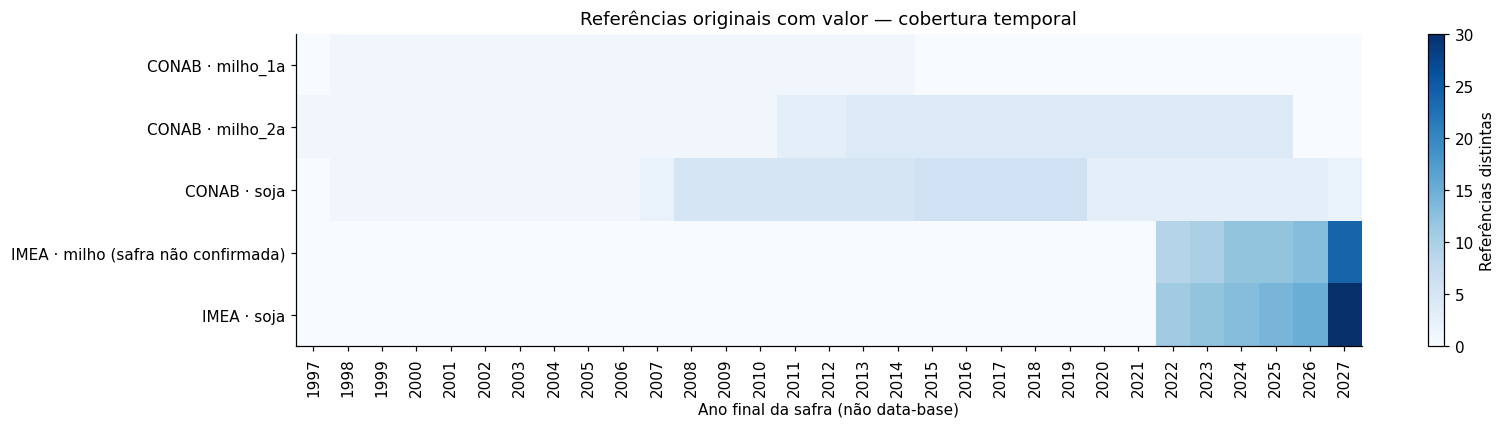

,grupo,abrangencia_origem,localidade,referencias,com_valor
0,CONAB · milho_1a,referência de praça,Primavera do Leste,17,17
1,CONAB · milho_2a,referência de praça,Campo Novo do Parecis,15,15
2,CONAB · milho_2a,referência de praça,Campo Verde,15,15
3,CONAB · milho_2a,referência de praça,Primavera do Leste,27,27
4,CONAB · milho_2a,referência de praça,Sorriso,15,15
5,CONAB · soja,referência de praça,Campo Novo do Parecis,25,25
6,CONAB · soja,referência de praça,Primavera do Leste,42,42
7,CONAB · soja,referência de praça,Sorriso,32,32
8,IMEA · milho (safra não confirmada),estado,MATO GROSSO,7,7
9,IMEA · milho (safra não confirmada),praca_municipal,ALTA FLORESTA,7,3


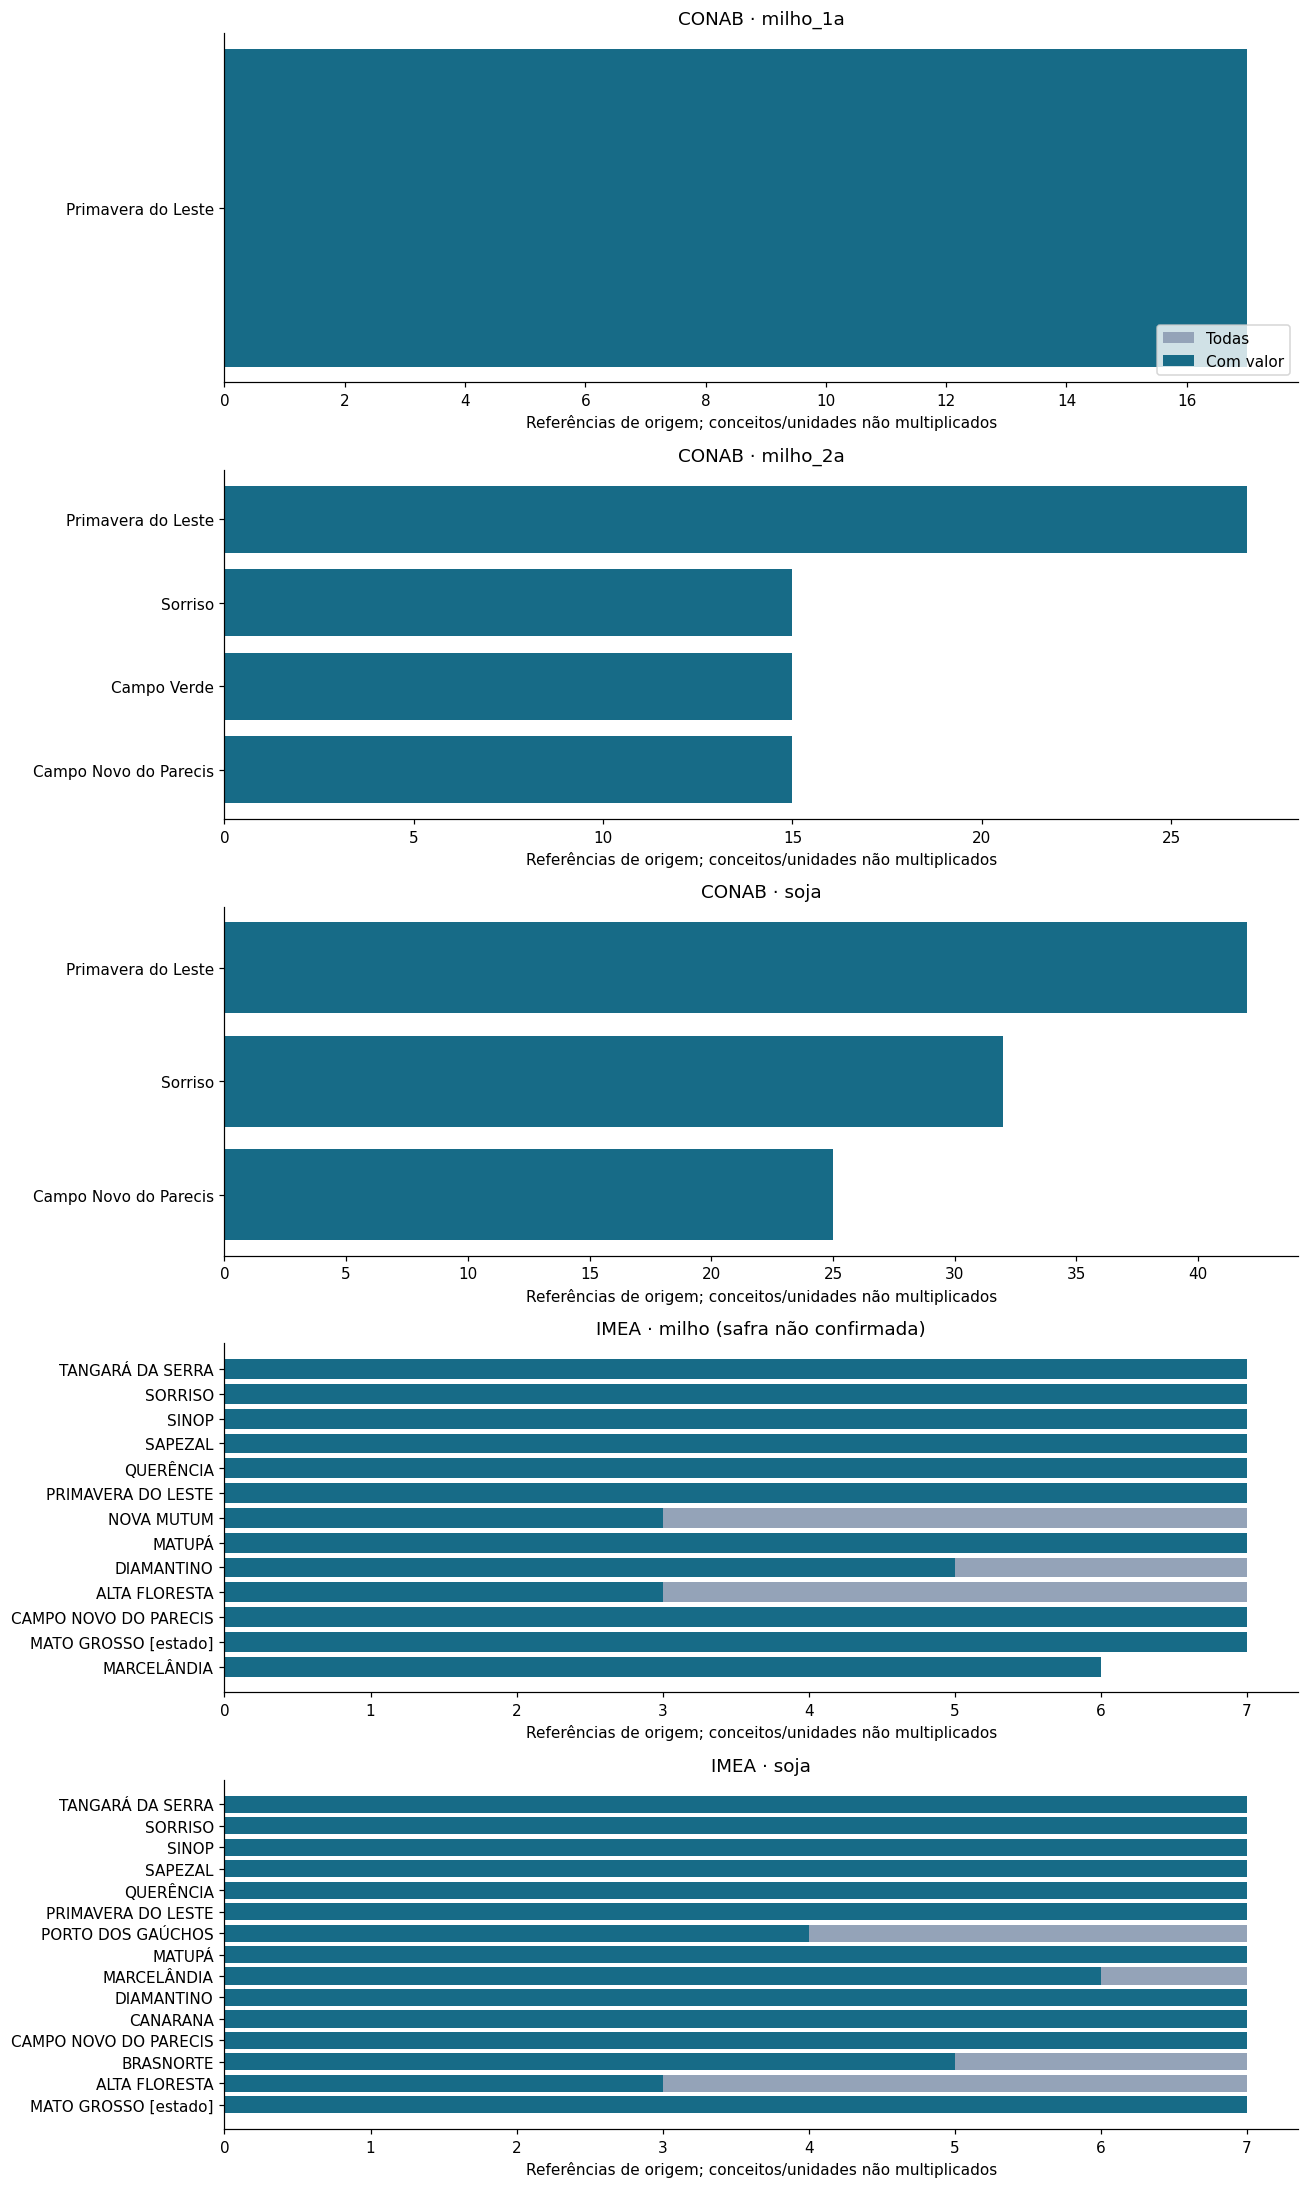

In [4]:
cobertura = refs.groupby(["grupo","ano_safra_fim"]).agg(referencias=("id_serie_origem","size"), com_valor=("tem_valor","sum")).reset_index()
display(cobertura)
display(refs.groupby("grupo").agg(data_base_min=("data_base",lambda s:s[s.ne("")].min() if s.ne("").any() else "NA"),data_base_max=("data_base",lambda s:s[s.ne("")].max() if s.ne("").any() else "NA")))
mat = cobertura.pivot(index="grupo",columns="ano_safra_fim",values="com_valor").reindex(columns=range(int(refs.ano_safra_fim.min()),int(refs.ano_safra_fim.max())+1)).fillna(0)
fig,ax=plt.subplots(figsize=(15,4))
im=ax.imshow(mat.values,aspect="auto",cmap="Blues")
ax.set_yticks(range(len(mat)),mat.index)
ax.set_xticks(range(len(mat.columns)),mat.columns,rotation=90)
ax.set(xlabel="Ano final da safra (não data-base)",title="Referências originais com valor — cobertura temporal")
fig.colorbar(im,ax=ax,label="Referências distintas")
fig.tight_layout(); plt.show()
geo=refs.groupby(["grupo","abrangencia_origem","localidade"]).agg(referencias=("id_serie_origem","size"),com_valor=("tem_valor","sum")).reset_index()
display(geo)
groups=sorted(refs.grupo.unique())
fig,axes=plt.subplots(len(groups),1,figsize=(12,20))
for ax,g in zip(axes,groups):
    z=geo[geo.grupo.eq(g)].sort_values("referencias")
    labels=z.localidade + np.where(z.abrangencia_origem.eq("estado")," [estado]","")
    ax.barh(labels,z.referencias,color="#94a3b8",label="Todas")
    ax.barh(labels,z.com_valor,color="#176b87",label="Com valor")
    ax.set(title=g,xlabel="Referências de origem; conceitos/unidades não multiplicados")
axes[0].legend(loc="lower right")
fig.tight_layout(); plt.show()


## 4. Estatísticas dos valores nominais

Estratificação por fonte, cultura/safra, sistema, conceito e unidade. As estatísticas do inventário inteiro misturam **anos de preços nominais**, apenas para diagnóstico de escala e dispersão, e não comparam custos reais. A composição das praças varia. Não somamos conceitos A–J, nem custos por hectare com custos por saca. Percentis não são intervalos de confiança; a amostra não é probabilística.

Para gráficos de distribuição mais legíveis, usamos somente ano final de safra **2024**, valores por hectare e os conceitos H/J CONAB e COE/COT/CT IMEA. CONAB fica separado por tecnologia; no IMEA usamos apenas consolidados de praças, excluindo o agregado estadual para não contar a abrangência sobreposta na distribuição. As estatísticas tabulares mantêm estado e praça em estratos separados. Mesmo nessa janela, datas-base podem diferir: não é comparação causal ou de preços reais.

n  \
fonte cultura_sistema_origem    sistema_tecnologia     abrangencia_origem  conceito_codigo_extrato unidade_original       
CONAB milho_1a                  não declarada          referência de praça A                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           B                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           C                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           D                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           E                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           F                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           G                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           H                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           I                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
                                                                           J                       BRL_nominal/60kg  17   
                                                                                                   BRL_nominal/ha    17   
      milho_2a                  OGM                    referência de praça A                       BRL_nominal/60kg  47   
                                                                                                   BRL_nominal/ha    47   
                                                                           B                       BRL_nominal/60kg  47   
                                                                                                   BRL_nominal/ha    47   
                                                                           C                       BRL_nominal/60kg  47   
                                                                                                   BRL_nominal/ha    47   
                                                                           D                       BRL_nominal/60kg  47   
                                                                                                   BRL_nominal/ha    47   
                                                                           E                       BRL_nominal/60kg  47   
                                                                                                   BRL_nominal/ha    47   
                                                                           F                       BRL_nominal/60kg  47   
                                                           

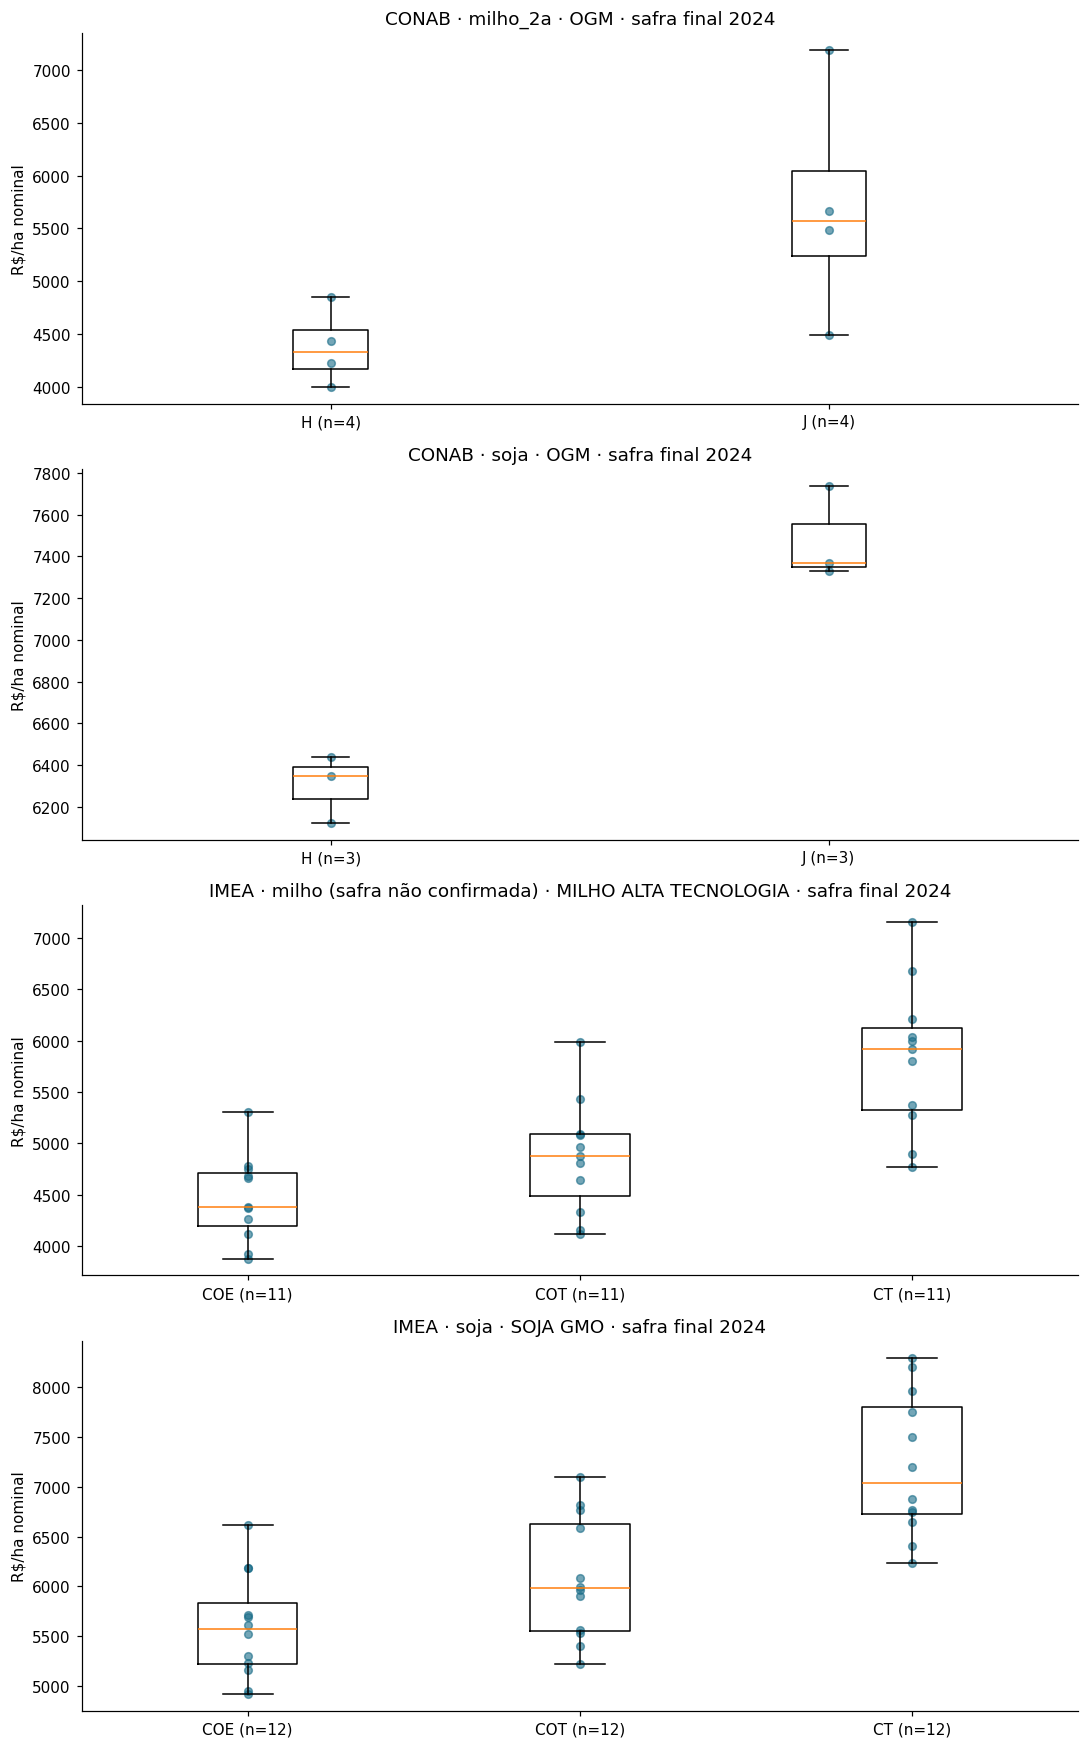

n  \
grupo                               sistema_tecnologia    conceito_codigo_extrato       
CONAB · milho_2a                    OGM                   H                         4   
                                                          J                         4   
CONAB · soja                        OGM                   H                         3   
                                                          J                         3   
IMEA · milho (safra não confirmada) MILHO ALTA TECNOLOGIA COE                      11   
                                                          COT                      11   
                                                          CT                       11   
IMEA · soja                         SOJA GMO              COE                      12   
                                                          COT                      12   
                                                          CT                       12   

                                                                                  data_base_min  \
grupo                               sistema_tecnologia    conceito_codigo_extrato                 
CONAB · milho_2a                    OGM                   H                             2024-03   
                                                          J                             2024-03   
CONAB · soja                        OGM                   H                             2023-03   
                                                          J                             2023-03   
IMEA · milho (safra não confirmada) MILHO ALTA TECNOLOGIA COE                                     
                                                          COT                                     
                                                          CT                                      
IMEA · soja                         SOJA GMO              COE                                     
                                                          COT                                     
                                                          CT                                      

                                                                                  data_base_max  
grupo                               sistema_tecnologia    conceito_codigo_extrato                
CONAB · milho_2a                    OGM                   H                             2024-03  
                                                          J                             2024-03  
CONAB · soja                        OGM                   H                             2023-03  
                                                          J                             2023-03  
IMEA · milho (safra não confirmada) MILHO ALTA TECNOLOGIA COE                                    
                                                          COT                                    
                                                          CT                                     
IMEA · soja                         SOJA GMO              COE                                    
                                                          COT                                    
                                                          CT

In [5]:
keys=["fonte","cultura_sistema_origem","sistema_tecnologia","abrangencia_origem","conceito_codigo_extrato","unidade_original"]
estat=df.groupby(keys).valor_num.agg(n="count",ausentes=lambda s:s.isna().sum(),media="mean",desvio="std",minimo="min",p25=lambda s:s.quantile(.25),mediana="median",p75=lambda s:s.quantile(.75),maximo="max")
with pd.option_context("display.max_rows", None):
    display(estat.round(2))
principal=df[((df.fonte.eq("CONAB")) & df.conceito_codigo_extrato.isin(["H","J"]) & df.unidade_original.eq("BRL_nominal/ha")) | ((df.fonte.eq("IMEA")) & df.conceito_codigo_extrato.isin(["COE","COT","CT"]) & df.natureza.eq("consolidado"))].copy()
recorte=principal[principal.ano_safra_fim.eq(2024) & principal.valor_num.notna() & principal.abrangencia_origem.ne("estado")]
panels=list(recorte.groupby(["grupo","sistema_tecnologia"],sort=True))
fig,axes=plt.subplots(len(panels),1,figsize=(10,4*len(panels)),squeeze=False)
for ax,((g,tech),z) in zip(axes.flat,panels):
    cs=sorted(z.conceito_codigo_extrato.unique())
    vals=[z[z.conceito_codigo_extrato.eq(k)].valor_num.values for k in cs]
    ax.boxplot(vals,tick_labels=[f"{k} (n={len(v)})" for k,v in zip(cs,vals)],showfliers=False)
    for i,v in enumerate(vals,1): ax.scatter(np.full(len(v),i),v,alpha=.6,s=25,color="#176b87")
    ax.set(title=f"{g} · {tech} · safra final 2024",ylabel="R$/ha nominal")
fig.tight_layout(); plt.show()
display(recorte.groupby(["grupo","sistema_tecnologia","conceito_codigo_extrato"]).agg(n=("valor_num","size"),data_base_min=("data_base","min"),data_base_max=("data_base","max")))


## 5. Evolução nominal em séries identificadas

Para evitar misturar praças e tecnologias, selecionamos, em cada grupo, a combinação localidade × sistema com mais anos distintos no subconjunto H/J ou COE/COT/CT. Empates são resolvidos pela ordem textual. A seleção é descritiva, não baseada no valor dos custos ou em ajuste preditivo. Excluímos desta visualização referências CONAB com conflito/ambiguidade geográfica sinalizados; elas permanecem no inventário.

CONAB usa **ano da data-base**; IMEA usa **ano final da safra consolidada**, pois não há mês nominal suficiente. Painéis não têm calendário ou escala monetária real harmonizados. Cada ponto é um valor publicado; não traçamos médias nem ligamos pontos para preencher lacunas. CONAB Ex-Ant permanece identificado pela fonte e não comprova disponibilidade histórica. As curvas não serão usadas como previsão nesta etapa.

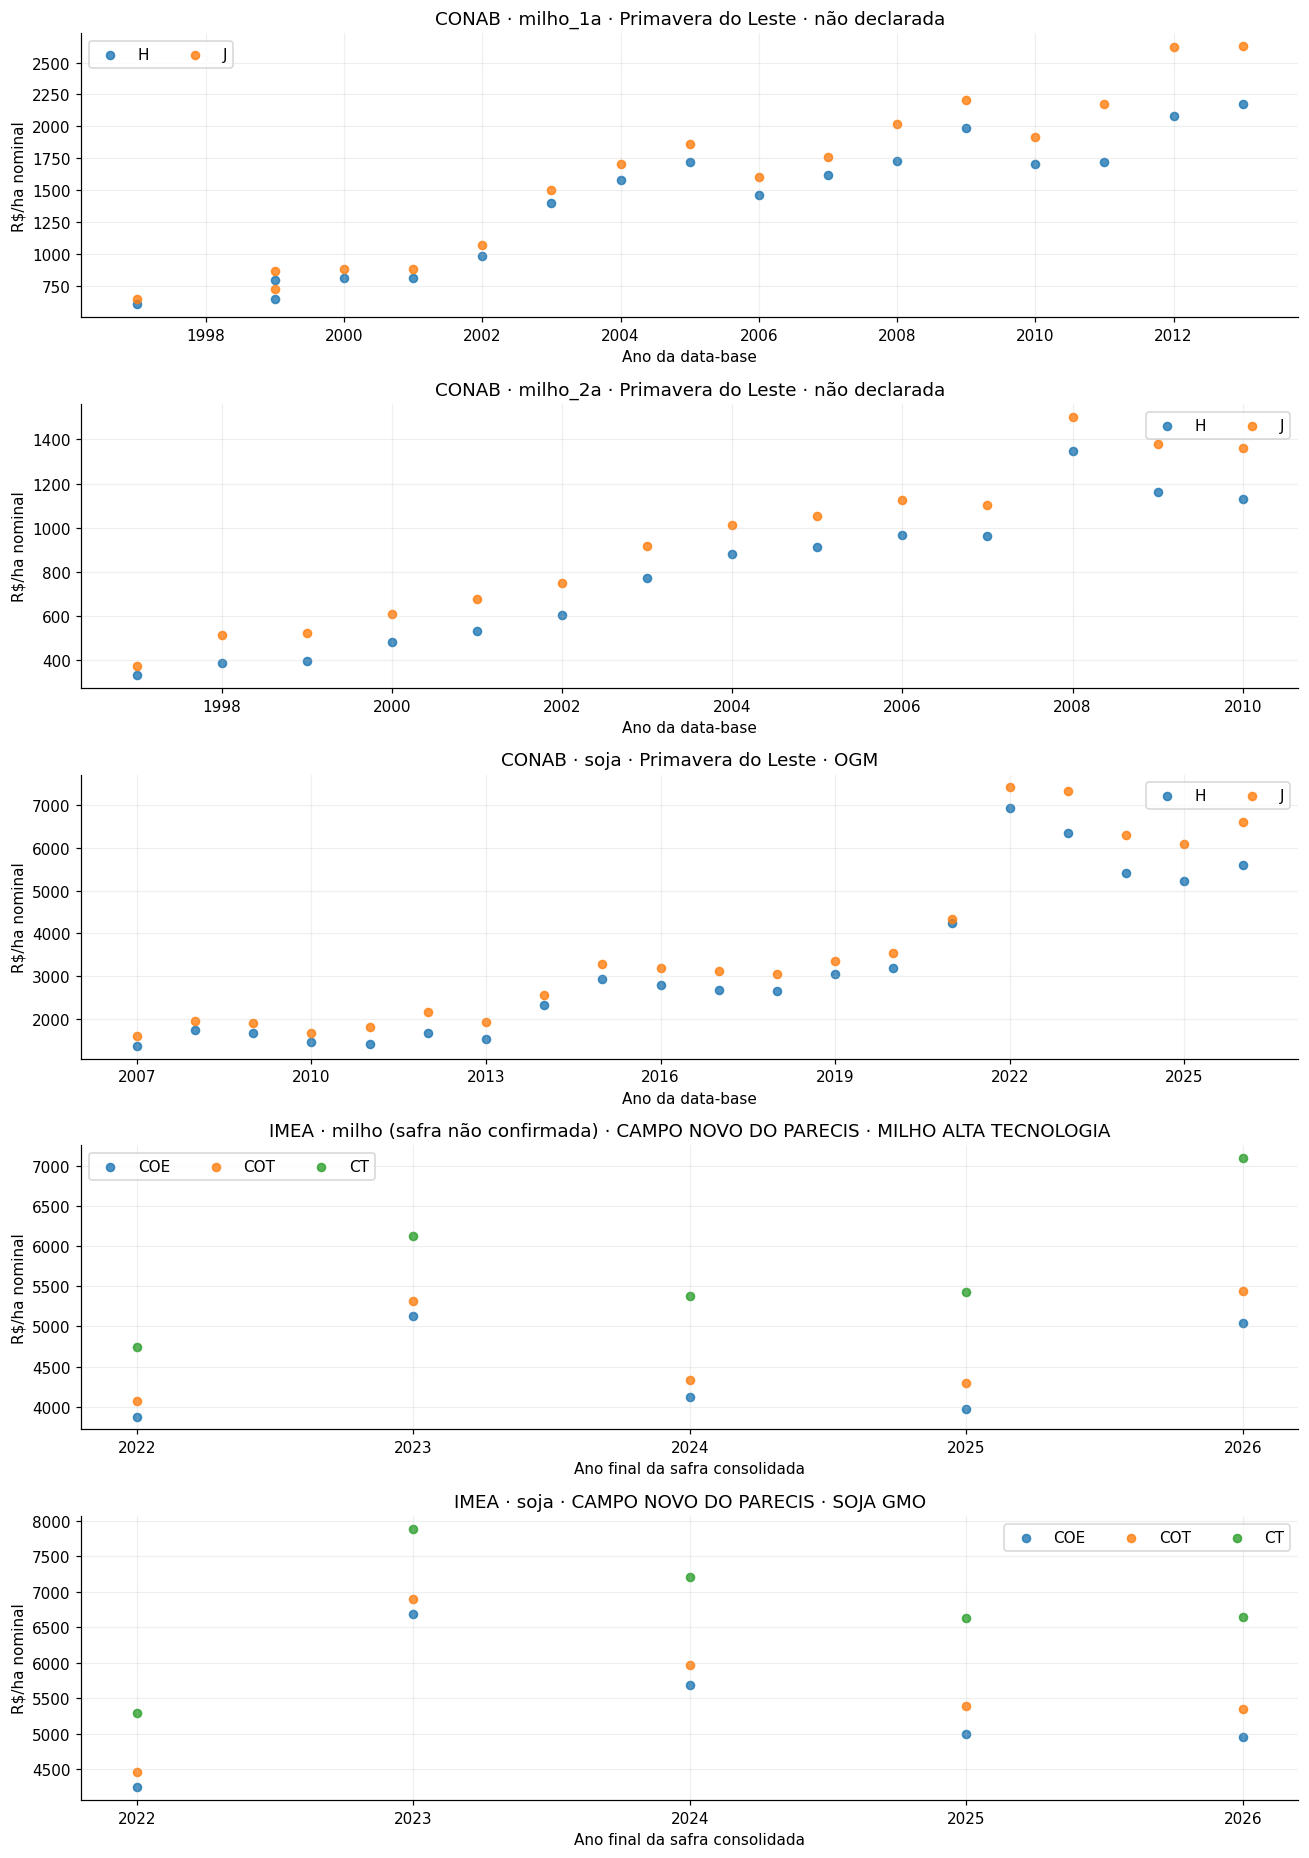

,grupo,localidade,sistema_tecnologia,anos,referencias
0,CONAB · milho_1a,Primavera do Leste,não declarada,16,17
1,CONAB · milho_2a,Primavera do Leste,não declarada,14,14
2,CONAB · soja,Primavera do Leste,OGM,20,20
3,IMEA · milho (safra não confirmada),CAMPO NOVO DO PARECIS,MILHO ALTA TECNOLOGIA,5,5
4,IMEA · soja,CAMPO NOVO DO PARECIS,SOJA GMO,5,5


In [6]:
evol=principal[principal.valor_num.notna()].copy()
def geo_ok(row):
    f=json.loads(row.alertas_extrato_json)
    return row.fonte!="CONAB" or (f.get("conflito_praca")!="True" and f.get("praca_ambigua")!="True")
evol=evol[evol.apply(geo_ok,axis=1)].copy()
evol["ano_plot"]=evol.ano_data_base.where(evol.fonte.eq("CONAB"),evol.ano_safra_fim)
selecao=[]
fig,axes=plt.subplots(evol.grupo.nunique(),1,figsize=(12,17))
for ax,(g,z) in zip(axes,evol.groupby("grupo",sort=True)):
    ranking=z.groupby(["localidade","sistema_tecnologia"]).ano_plot.nunique().reset_index(name="anos").sort_values(["anos","localidade","sistema_tecnologia"],ascending=[False,True,True])
    best=ranking.iloc[0]
    v=z[z.localidade.eq(best.localidade)&z.sistema_tecnologia.eq(best.sistema_tecnologia)]
    selecao.append({"grupo":g,**best.to_dict(),"referencias":v.id_serie_origem.nunique()})
    for k,w in v.groupby("conceito_codigo_extrato"):
        ax.scatter(w.ano_plot.astype(float),w.valor_num,label=k,s=28,alpha=.8)
    eixo="Ano da data-base" if g.startswith("CONAB") else "Ano final da safra consolidada"
    ax.set(title=f"{g} · {best.localidade} · {best.sistema_tecnologia}",xlabel=eixo,ylabel="R$/ha nominal")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(ncol=3); ax.grid(alpha=.2)
fig.tight_layout(); plt.show()
display(pd.DataFrame(selecao))


## 6. Lacunas e próximos passos possíveis

Ausência de lacunas no conjunto de anos de um grupo não implica painel completo por praça ou tecnologia: a composição muda e há referências sem valor. Esta descrição não resolve compatibilidade contábil, monetária ou de safra. Antes de qualquer backcasting, será necessário delimitar fonte, conceito, tecnologia, praça e período-alvo; verificar vintages/data-base e razões das ausências; avaliar mudanças de pacote tecnológico e disponibilidade real de preditores. A ausência de município/ano não deve virar zero, interpolação automática ou série sintética.

H e J são blocos diferentes na CONAB; COE/COT/CT são conceitos IMEA, sem ponte validada. Milho IMEA não foi classificado em 1ª/2ª safra. O milho CONAB é separado, enquanto receitas PAM do projeto são agregadas. A base preserva alertas contábeis e geográficos; uma referência com valor não é necessariamente elegível para análise econométrica. Seleção de amostra e eventual harmonização exigirão decisões próprias, posteriores a este inventário.

In [7]:
# Conclusões numéricas calculadas do arquivo efetivamente lido.
for g,z in refs.groupby("grupo"):
    anos=sorted(z.ano_safra_fim.dropna().astype(int).unique())
    faltam=sorted(set(range(min(anos),max(anos)+1))-set(anos))
    print(f"{g}: {len(z)} referências, {int(z.tem_valor.sum())} com valor, {z.localidade.nunique()} rótulos geográficos; safra final {min(anos)}–{max(anos)}; anos sem referência no intervalo: {faltam or 'nenhum'}.")
print("\nValores ausentes por fonte:",df.groupby("fonte").valor_num.apply(lambda s:int(s.isna().sum())).to_dict())
print("CONAB: referências com Ex-Ant literal =",int((refs.fonte.eq("CONAB") & refs.flag_ex_ant.eq("True")).sum()))
print("IMEA: referências sem data-base =",int((refs.fonte.eq("IMEA") & refs.data_base.eq("")).sum()))
assert hashlib.sha256(CSV.read_bytes()).hexdigest()==sha_antes
pd.testing.assert_frame_equal(raw,pd.read_csv(CSV,dtype=str,keep_default_na=False))
print("\nIntegridade confirmada: CSV idêntico por SHA256 e valores; nenhuma gravação, previsão, imputação ou conversão monetária.")


CONAB · milho_1a: 17 referências, 17 com valor, 1 rótulos geográficos; safra final 1998–2014; anos sem referência no intervalo: nenhum.
CONAB · milho_2a: 72 referências, 72 com valor, 4 rótulos geográficos; safra final 1997–2025; anos sem referência no intervalo: nenhum.
CONAB · soja: 99 referências, 99 com valor, 3 rótulos geográficos; safra final 1998–2027; anos sem referência no intervalo: nenhum.
IMEA · milho (safra não confirmada): 90 referências, 80 com valor, 13 rótulos geográficos; safra final 2021–2027; anos sem referência no intervalo: nenhum.
IMEA · soja: 105 referências, 95 com valor, 15 rótulos geográficos; safra final 2022–2027; anos sem referência no intervalo: nenhum.

Valores ausentes por fonte: {'CONAB': 0, 'IMEA': 60}
CONAB: referências com Ex-Ant literal = 126
IMEA: referências sem data-base = 195

Integridade confirmada: CSV idêntico por SHA256 e valores; nenhuma gravação, previsão, imputação ou conversão monetária.
